# 10 · Category prevalence (long tail)

**What it does.** Manuscript-style (Clerkin) prevalence for any of `bv vedb imagenet lvis` (THINGS has a fixed number
of images per category, so no prevalence):
- **BV, VEDB:** share of frames with a CLIP-passing detection of the category (manuscript notebook 01 / VEDB tables).
- **LVIS:** share of images with ≥1 labeled box from the category's pool. LVIS labels each category on a **capped** set
  of images (≤2,364; person has 1,928 labeled training images), so this reflects the labeling protocol, not how
  often objects appear.
- **ImageNet:** share of images in the pooled classes. One label per image, ~1,300 images per class, so this mostly
  counts classes per word.
- **Native distributions** (no CDI pooling) for ImageNet's 1,000 classes and LVIS's 1,203 categories.

**Outputs:** `outputs/category_prevalence/results/` and `figures/`, named by the chosen datasets.

In [1]:
# Standard setup shared by every notebook (each notebook is self-contained).
import json
import os
import random
import re
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch, Rectangle
from scipy.cluster.hierarchy import leaves_list, linkage, optimal_leaf_ordering
from scipy.spatial.distance import pdist, squareform
from scipy.stats import false_discovery_control, pearsonr, rankdata, spearmanr, wilcoxon
from IPython.display import Image, Markdown, display

plt.rcParams["font.family"] = ["DejaVu Sans", "sans-serif"]
pd.set_option("display.max_colwidth", 120)


def show_images(paths, width=950):
    """Display saved figures (the files this notebook writes)."""
    for p in map(Path, paths):
        if p.exists():
            display(Markdown(f"`{p.relative_to(ROOT)}`")); display(Image(filename=str(p), width=width))
        else:
            display(Markdown(f"*Missing figure:* `{p}`"))

In [2]:
# Paths. Run this notebook from analysis/comparison-datasets/notebooks/ (Jupyter's default working directory).
ROOT = Path.cwd().resolve().parent                     # analysis/comparison-datasets
assert (ROOT / "notebooks").is_dir(), "open this notebook from analysis/comparison-datasets/notebooks/"
REPO = ROOT.parents[1]
DATA_DIR = REPO / "data"
MANUSCRIPT_DIR = REPO / "analysis" / "manuscript-2026"
VEDB_DIR = REPO / "analysis" / "vedb-1612"
VOCAB_DIR = DATA_DIR / "vocabulary_lists"
VALID129_TXT = VOCAB_DIR / "included_categories_valid129.txt"

# Inputs written by other pipelines (read only).
EXEMPLAR_EMBED_ROOT = Path(os.environ.get("BV_EXEMPLAR_EMBED_ROOT",
                                          str(MANUSCRIPT_DIR / "exemplar_set_embeddings"))).expanduser()
BV_THINGS_VALID129 = EXEMPLAR_EMBED_ROOT / "valid129"       # manuscript Stage 0: BV + THINGS tables
VEDB_VALID129 = VEDB_DIR / "exemplar_set_embeddings" / "valid129"   # vedb-1612 Stage 0 (files use the "bv_" prefix)

# External data on ccn2.
IMAGENET_DIR = Path("/data2/j7yang/imagenet-1k/extracted")
IMAGENET_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/imagenet_1k/outputs/image_embeddings")
LVIS_ROOT = Path("/data2/j7yang/lvis")
LVIS_CROP_EMBED_ROOT = Path("/ccn2a/dataset/babyview/related_data/lvis/outputs/crop_embeddings")

# Outputs of this folder.
OUT = ROOT / "outputs"
MAPPING_OUT = OUT / "mapping"
MONTAGE_OUT = OUT / "montages"
EXEMPLAR_SETS = OUT / "exemplar_sets"
MODELS = ("clip", "dinov3")

## Parameters
Any of `bv vedb imagenet lvis`.

In [3]:
DATASETS = ["bv", "vedb", "imagenet", "lvis"]

_allowed = ('bv', 'vedb', 'imagenet', 'lvis')
assert set(DATASETS) <= set(_allowed) and len(set(DATASETS)) >= 1, f"DATASETS must be 1+ of {_allowed}"
DATASETS = [d for d in _allowed if d in DATASETS]   # fixed display order

## Shared helpers

In [4]:
def load_cdi_semantic_map() -> dict[str, str]:
    """``uni_lemma`` → CDI semantic domain from ``data/cdi_words.csv``.

    Frequency tables under ``data/long_tailed_dist_prop_included_categories_*.csv``
    are not a semantic source: the unfiltered valid129 file currently copies
    valid85 labels and marks the extra 44 categories as ``other``.
    """
    import pandas as pd

    path = DATA_DIR / "cdi_words.csv"
    df = pd.read_csv(path, usecols=["uni_lemma", "category"])
    df["uni_lemma"] = df["uni_lemma"].astype(str).str.strip().str.lower()
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return (
        df.drop_duplicates(subset=["uni_lemma"], keep="first")
        .set_index("uni_lemma")["category"]
        .to_dict()
    )


# Dataset registry and raw-table loading (shared helpers; repeated in each notebook that needs them).
ALL_DATASETS = ("bv", "vedb", "things", "imagenet", "lvis")
LABEL = {"bv": "BV", "vedb": "VEDB", "things": "THINGS", "imagenet": "ImageNet", "lvis": "LVIS"}
COLOR = {"bv": "#90caf9", "vedb": "#0d47a1", "imagenet": "#eb6834", "lvis": "#1baf7a", "things": "#eda100"}
COMPARISON_SETS = {"imagenet": "imagenet_exclusive75", "lvis": "lvis_exclusive104"}


def zscore_rows(X: np.ndarray, eps: float = 1e-10) -> np.ndarray:
    """Same as manuscript notebook 07: z-score each dimension across categories."""
    return (X - X.mean(axis=0)) / (X.std(axis=0) + eps)


def raw_path(ds: str, model: str) -> Path:
    if ds in COMPARISON_SETS:
        s = COMPARISON_SETS[ds]
        return EXEMPLAR_SETS / s / f"{ds}_{model}_exemplar_avg_raw_within_{s}.csv"
    if ds == "vedb":
        return VEDB_VALID129 / f"bv_{model}_exemplar_avg_raw_within_valid129.csv"
    return BV_THINGS_VALID129 / f"{ds}_{model}_exemplar_avg_raw_within_valid129.csv"


def load_raw(path: Path, cats: list[str]) -> np.ndarray:
    df = pd.read_csv(path)
    df["category"] = df["category"].astype(str).str.strip().str.lower()
    return df.set_index("category").loc[cats].filter(like="dim_").to_numpy(dtype=np.float64)


def shared_categories(datasets) -> list[str]:
    """Categories present in every given dataset's table, for both models (sorted)."""
    present = None
    for ds in datasets:
        for model in MODELS:
            cats = set(pd.read_csv(raw_path(ds, model), usecols=["category"])["category"].str.strip().str.lower())
            present = cats if present is None else present & cats
    return sorted(present)


def zscored_tables(datasets, cats, model) -> dict[str, np.ndarray]:
    """{dataset: category x dim matrix}, each z-scored within cats."""
    return {ds: zscore_rows(load_raw(raw_path(ds, model), cats)) for ds in datasets}

## Prevalence per dataset

In [5]:
PREVALENCE_DATASETS = ("bv", "vedb", "imagenet", "lvis")
TABLE = "long_tailed_dist_prop_included_categories_filtered-0.27_valid129.csv"
BV_TABLE = MANUSCRIPT_DIR / "main_results_valid129s_04302026" / "results" / TABLE
VEDB_TABLE = VEDB_DIR / "analyses" / "valid129" / "results" / TABLE
OUT_DIR = OUT / "category_prevalence"
LABEL_SPOT = {"bv": (10**6, 0), "vedb": (10**6, 0), "imagenet": (45, -8), "lvis": (35, 8)}


def video_prevalence(path: Path, ds: str) -> pd.DataFrame:
    t = pd.read_csv(path)
    t = t[t["count_frames"] > 0]  # VEDB has no detections of some valid129 words (e.g. mouth)
    return pd.DataFrame({"dataset": ds, "category": t["category"], "count": t["count_frames"],
                         "total": t["total_frames"], "unit": "frames"})


def lvis_prevalence() -> pd.DataFrame:
    meta = pd.read_csv(MAPPING_OUT / "lvis_crop_metadata.csv.gz", usecols=["coco_image_id", "category_id"])
    total = meta["coco_image_id"].nunique()  # images with any box of a CDI-mapped LVIS category
    pools = pd.read_csv(EXEMPLAR_SETS / "lvis_exclusive104" / "lvis_category_classes.csv")
    m = meta.merge(pools[["cdi_category", "lvis_category_id"]], left_on="category_id", right_on="lvis_category_id")
    n = m.groupby("cdi_category")["coco_image_id"].nunique()
    return pd.DataFrame({"dataset": "lvis", "category": n.index, "count": n.values, "total": total, "unit": "images"})


def imagenet_prevalence() -> pd.DataFrame:
    hmap = pd.read_csv(MAPPING_OUT / "imagenet_cdi_hyponym_map.csv")
    per_class = hmap.drop_duplicates("wnid").set_index("wnid")
    total = int((per_class["n_train"] + per_class["n_val"]).sum())  # images in any CDI-mapped class
    pools = pd.read_csv(EXEMPLAR_SETS / "imagenet_exclusive75" / "imagenet_category_classes.csv")
    pools["n"] = pools["wnid"].map(per_class["n_train"] + per_class["n_val"])
    n = pools.groupby("cdi_category")["n"].sum()
    return pd.DataFrame({"dataset": "imagenet", "category": n.index, "count": n.values.astype(int),
                         "total": total, "unit": "images"})


def native_imagenet() -> pd.DataFrame:
    """All 1,000 ImageNet classes: images per class (train + val) / all images."""
    import numpy as np_
    from nltk.corpus import wordnet as wn
    npz = np_.load(MAPPING_OUT / "imagenet_class_embeddings_clip.npz")
    wnids = [str(w) for w in npz["wnids"]]
    analyzed = pd.read_csv(EXEMPLAR_SETS / "imagenet_exclusive75" / "imagenet_category_classes.csv")
    to_cdi = dict(zip(analyzed["wnid"], analyzed["cdi_category"]))
    t = pd.DataFrame({"class_id": wnids,
                      "class_name": [wn.synset_from_pos_and_offset("n", int(w[1:])).lemma_names()[0] for w in wnids],
                      "count": npz["counts"].astype(int)})
    t["total"] = int(t["count"].sum())
    t["cdi_category"] = t["class_id"].map(to_cdi).fillna("")
    return t


def native_lvis() -> pd.DataFrame:
    """All 1,203 LVIS categories: images with >=1 box (train + val annotations) / all LVIS images."""
    import json
    n_images, cats = 0, None
    img_sets = {}
    for split in ("train", "val"):
        d = json.load(open(LVIS_ROOT / "annotations" / f"lvis_v1_{split}.json"))
        cats = cats or d["categories"]
        n_images += len(d["images"])
        for a in d["annotations"]:
            img_sets.setdefault(a["category_id"], set()).add(a["image_id"])
    analyzed = pd.read_csv(EXEMPLAR_SETS / "lvis_exclusive104" / "lvis_category_classes.csv")
    to_cdi = dict(zip(analyzed["lvis_category_id"], analyzed["cdi_category"]))
    t = pd.DataFrame({"class_id": [c["id"] for c in cats], "class_name": [c["name"] for c in cats],
                      "lvis_frequency": [c["frequency"] for c in cats],
                      "count": [len(img_sets.get(c["id"], ())) for c in cats]})
    t["total"] = n_images
    t["cdi_category"] = t["class_id"].map(to_cdi).fillna("")
    return t

## Figures

In [6]:
def plot_native(tables: dict, path: Path) -> None:
    fig, axes = plt.subplots(1, len(tables), figsize=(6.5 * len(tables), 5.4), sharey=True,
                             constrained_layout=True, squeeze=False)
    axes = axes[0]
    for ax, (ds, t) in zip(axes, tables.items()):
        t = t.sort_values("prevalence", ascending=False).reset_index(drop=True)
        t["rank"] = np.arange(1, len(t) + 1)
        ax.plot(t["rank"], t["prevalence"], color="#b9b8b2", lw=1.5, zorder=1)
        hit = t[t["cdi_category"] != ""]
        ax.scatter(t.loc[t["cdi_category"] == "", "rank"], t.loc[t["cdi_category"] == "", "prevalence"],
                   s=10, color="#b9b8b2", zorder=2, label="not in an analyzed CDI category")
        ax.scatter(hit["rank"], hit["prevalence"], s=14, color=COLOR[ds], edgecolor="white", linewidth=0.4,
                   zorder=3, label=f"feeds an analyzed CDI category ({len(hit)})")
        if ds == "lvis":  # federated labeling caps the images labeled per category
            cap = t["prevalence"].max()
            ax.axhline(cap, color="#52514e", lw=0.8, ls="--", zorder=0)
            ax.annotate(f"labeling cap: ≤{int(t['count'].max()):,} images per category", (len(t), cap),
                        xytext=(0, 5), textcoords="offset points", ha="right", va="bottom", fontsize=8.5,
                        color="#52514e")
        ax.set_yscale("log")
        unit = "images in the class" if ds == "imagenet" else "images with ≥1 box"
        ax.set_title(f"{LABEL[ds]}: all {len(t):,} native classes (share of {unit})", fontsize=11)
        ax.set_xlabel("Native class rank")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", which="major", color="#e6e5e0", lw=0.6)
        ax.set_axisbelow(True)
        ax.legend(frameon=False, fontsize=8.5, loc="lower left")
    axes[0].set_ylabel("Prevalence (log scale)")
    axes[0].set_ylim(5e-6, 0.3)
    fig.text(0.5, -0.03, "No CDI pooling: each point is one ImageNet class or LVIS category. Neither curve is a natural "
             "frequency. ImageNet has ~1,300 training images per class by design. LVIS labels each category\non a capped "
             "set of images (person, the most common COCO object, has 1,928 labeled training images), so its frequent "
             "categories pile up at the cap.", ha="center", va="top", fontsize=8.5, color="#52514e")
    fig.savefig(path.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)


def plot_rank_curves(df: pd.DataFrame, datasets, path: Path) -> None:
    fig, ax = plt.subplots(figsize=(9.5, 5.6), constrained_layout=True)
    for ds in datasets:
        d = df[df["dataset"] == ds].sort_values("rank")
        ax.plot(d["rank"], d["prevalence"], color=COLOR[ds], lw=2, marker="o", ms=4.5,
                markeredgecolor="white", markeredgewidth=0.6, label=f"{LABEL[ds]} ({len(d)} categories)")
        # Direct labels where nothing else is drawn: BV / VEDB at their line ends; ImageNet below and
        # LVIS above their own plateaus (their line ends sit on top of the other curves).
        at_rank, dy = LABEL_SPOT[ds]
        pt = d[d["rank"] == min(at_rank, len(d))].iloc[0]
        ax.annotate(LABEL[ds], (pt["rank"], pt["prevalence"]), xytext=(6 if dy == 0 else 0, dy),
                    textcoords="offset points", ha="left" if dy == 0 else "center",
                    va="center" if dy == 0 else ("bottom" if dy > 0 else "top"), fontsize=10, color="#333333")
    ax.set_yscale("log")
    ax.set_xlabel("Category rank (most to least prevalent)")
    ax.set_ylabel("Prevalence: share of frames / images containing the category")
    ax.set_title("Category prevalence by dataset (each dataset on its analyzed categories)", fontsize=12)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", which="major", color="#e6e5e0", lw=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9, loc="upper right")
    fig.text(0.5, -0.04,
             "BV, VEDB: frames with a CLIP-passing detection. LVIS: images with a labeled box; LVIS caps the images "
             "labeled per category (≤2,364), so its curve reflects the labeling protocol.\nImageNet: one label per "
             "image, ~1,300 images per class, so its curve mostly reflects how many classes each category pools.", ha="center", va="top", fontsize=8.5, color="#52514e")
    fig.savefig(path.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)


def plot_shared(df: pd.DataFrame, datasets, shared: list[str], sem: dict, path: Path) -> None:
    wide = df[df["category"].isin(shared)].pivot(index="category", columns="dataset", values="prevalence")
    by = "bv" if "bv" in datasets else datasets[0]
    wide = wide.loc[wide[by].sort_values(ascending=True).index]  # most prevalent at the top
    n = len(wide)
    fig, ax = plt.subplots(figsize=(8.5, 0.19 * n + 1.6), constrained_layout=True)
    y = np.arange(n)
    lo, hi = wide.min(axis=1), wide.max(axis=1)
    ax.hlines(y, lo, hi, color="#d8d7d2", lw=1, zorder=1)
    for ds in datasets:
        ax.scatter(wide[ds], y, s=26, color=COLOR[ds], edgecolor="white", linewidth=0.5, zorder=2, label=LABEL[ds])
    ax.set_xscale("log")
    ax.set_yticks(y)
    ax.set_yticklabels(wide.index, fontsize=7.5)
    ax.set_ylim(-0.8, n - 0.2)
    ax.set_xlabel("Prevalence (log scale)")
    ax.set_title(f"Prevalence of the {n} categories shared by {', '.join(LABEL[d] for d in datasets)} "
                 f"(sorted by {LABEL[by]})", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", which="major", color="#e6e5e0", lw=0.6)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, fontsize=9, loc="lower right")
    fig.savefig(path.with_suffix(".png"), dpi=200, bbox_inches="tight")
    fig.savefig(path.with_suffix(".pdf"), bbox_inches="tight")
    plt.close(fig)

## The analysis

In [7]:
def category_prevalence(datasets=PREVALENCE_DATASETS):
    """Prevalence for the given datasets (CDI-pooled), their rank curves and shared-category comparison,
    plus native ImageNet / LVIS distributions when those are included; return the tables."""
    datasets = [d for d in PREVALENCE_DATASETS if d in datasets]  # fixed display order
    tag = "_".join(datasets)
    (OUT_DIR / "results").mkdir(parents=True, exist_ok=True)
    (OUT_DIR / "figures").mkdir(parents=True, exist_ok=True)
    sem = load_cdi_semantic_map()
    builders = {"bv": lambda: video_prevalence(BV_TABLE, "bv"), "vedb": lambda: video_prevalence(VEDB_TABLE, "vedb"),
                "imagenet": imagenet_prevalence, "lvis": lvis_prevalence}
    df = pd.concat([builders[ds]() for ds in datasets], ignore_index=True)
    df["prevalence"] = df["count"] / df["total"]
    df["rank"] = df.groupby("dataset")["prevalence"].rank(ascending=False, method="first").astype(int)
    df["cdi_semantic"] = df["category"].map(lambda c: sem.get(c, "other"))
    df = df.sort_values(["dataset", "rank"])
    df.to_csv(OUT_DIR / "results" / f"category_prevalence_{tag}.csv", index=False)
    plot_rank_curves(df, datasets, OUT_DIR / "figures" / f"prevalence_rank_curves_{tag}")

    shared, rows = [], []
    if len(datasets) >= 2:
        shared = sorted(set.intersection(*(set(df.loc[df["dataset"] == ds, "category"]) for ds in datasets)))
        wide = df[df["category"].isin(shared)].pivot(index="category", columns="dataset", values="prevalence")
        rows = [{"dataset_a": a, "dataset_b": b, "n_categories": len(shared),
                 "spearman_r": spearmanr(wide[a], wide[b])[0], "p": spearmanr(wide[a], wide[b])[1]}
                for a, b in combinations(datasets, 2)]
        pd.DataFrame(rows).to_csv(OUT_DIR / "results" / f"prevalence_spearman_{tag}.csv", index=False)
        plot_shared(df, datasets, shared, sem, OUT_DIR / "figures" / f"prevalence_shared_categories_{tag}")

    native_builders = {"imagenet": native_imagenet, "lvis": native_lvis}
    native = {ds: native_builders[ds]() for ds in datasets if ds in native_builders}
    for ds, t in native.items():
        t["prevalence"] = t["count"] / t["total"]
        t.sort_values("prevalence", ascending=False).to_csv(
            OUT_DIR / "results" / f"native_category_prevalence_{ds}.csv", index=False)
        a = t[t["cdi_category"] != ""]
        print(f"native {LABEL[ds]}: {len(t)} classes, pool {int(t['total'].iloc[0]):,} images; "
              f"prevalence max/median/min {t.prevalence.max():.4f}/{t.prevalence.median():.5f}/{t.prevalence.min():.6f}; "
              f"{len(a)} feed analyzed CDI categories (median {a.prevalence.median():.5f} vs "
              f"{t.loc[t.cdi_category == '', 'prevalence'].median():.5f} for the rest)")
    if native:
        plot_native(native, OUT_DIR / "figures" / f"prevalence_native_{'_'.join(native)}")

    for ds in datasets:
        d = df[df["dataset"] == ds]
        top = ", ".join(f"{r.category} {r.prevalence:.3f}" for r in d.nsmallest(5, "rank").itertuples())
        print(f"{LABEL[ds]:>8}: {len(d)} categories, pool {int(d['total'].iloc[0]):,} {d['unit'].iloc[0]}; "
              f"max/median/min {d.prevalence.max():.4f}/{d.prevalence.median():.4f}/{d.prevalence.min():.5f}; top: {top}")
    if shared:
        print(f"shared categories: {len(shared)}")
    for r in rows:
        print(f"  prevalence rank correlation {LABEL[r['dataset_a']]}-{LABEL[r['dataset_b']]}: "
              f"rho={r['spearman_r']:.2f} (p={r['p']:.1e})")
    return {"prevalence": df, "spearman": pd.DataFrame(rows), "native": native, "shared": shared}

## Run (~1 min; reads the LVIS annotations for the native distribution)

In [8]:
res = category_prevalence(DATASETS)
res['spearman'].round(3)

native ImageNet: 1000 classes, pool 1,331,167 images; prevalence max/median/min 0.0010/0.00101/0.000587; 326 feed analyzed CDI categories (median 0.00101 vs 0.00101 for the rest)
native LVIS: 1203 classes, pool 119,979 images; prevalence max/median/min 0.0197/0.00039/0.000008; 285 feed analyzed CDI categories (median 0.00077 vs 0.00032 for the rest)


      BV: 129 categories, pool 1,715,977 frames; max/median/min 0.1310/0.0019/0.00003; top: chair 0.131, lamp 0.106, table 0.094, couch 0.087, pillow 0.068
    VEDB: 128 categories, pool 732,703 frames; max/median/min 0.1460/0.0033/0.00001; top: chair 0.146, bottle 0.110, hand 0.101, door 0.089, window 0.086
ImageNet: 75 categories, pool 814,181 images; max/median/min 0.1889/0.0017/0.00115; top: dog 0.189, bird 0.098, fish 0.026, car 0.017, ball 0.015
    LVIS: 104 categories, pool 103,451 images; max/median/min 0.0628/0.0155/0.00026; top: shirt 0.063, glasses 0.062, table 0.044, glove 0.039, bottle 0.039
shared categories: 72
  prevalence rank correlation BV-VEDB: rho=0.78 (p=5.2e-16)
  prevalence rank correlation BV-ImageNet: rho=0.11 (p=3.5e-01)
  prevalence rank correlation BV-LVIS: rho=0.54 (p=8.3e-07)
  prevalence rank correlation VEDB-ImageNet: rho=0.15 (p=2.2e-01)
  prevalence rank correlation VEDB-LVIS: rho=0.66 (p=2.4e-10)
  prevalence rank correlation ImageNet-LVIS: rho=0.35

,dataset_a,dataset_b,n_categories,spearman_r,p
0,bv,vedb,72,0.782,0.000
1,bv,imagenet,72,0.112,0.348
2,bv,lvis,72,0.543,0.000
3,vedb,imagenet,72,0.148,0.215
4,vedb,lvis,72,0.662,0.000
5,imagenet,lvis,72,0.351,0.002


## Figures

`outputs/category_prevalence/figures/prevalence_rank_curves_bv_vedb_imagenet_lvis.png`

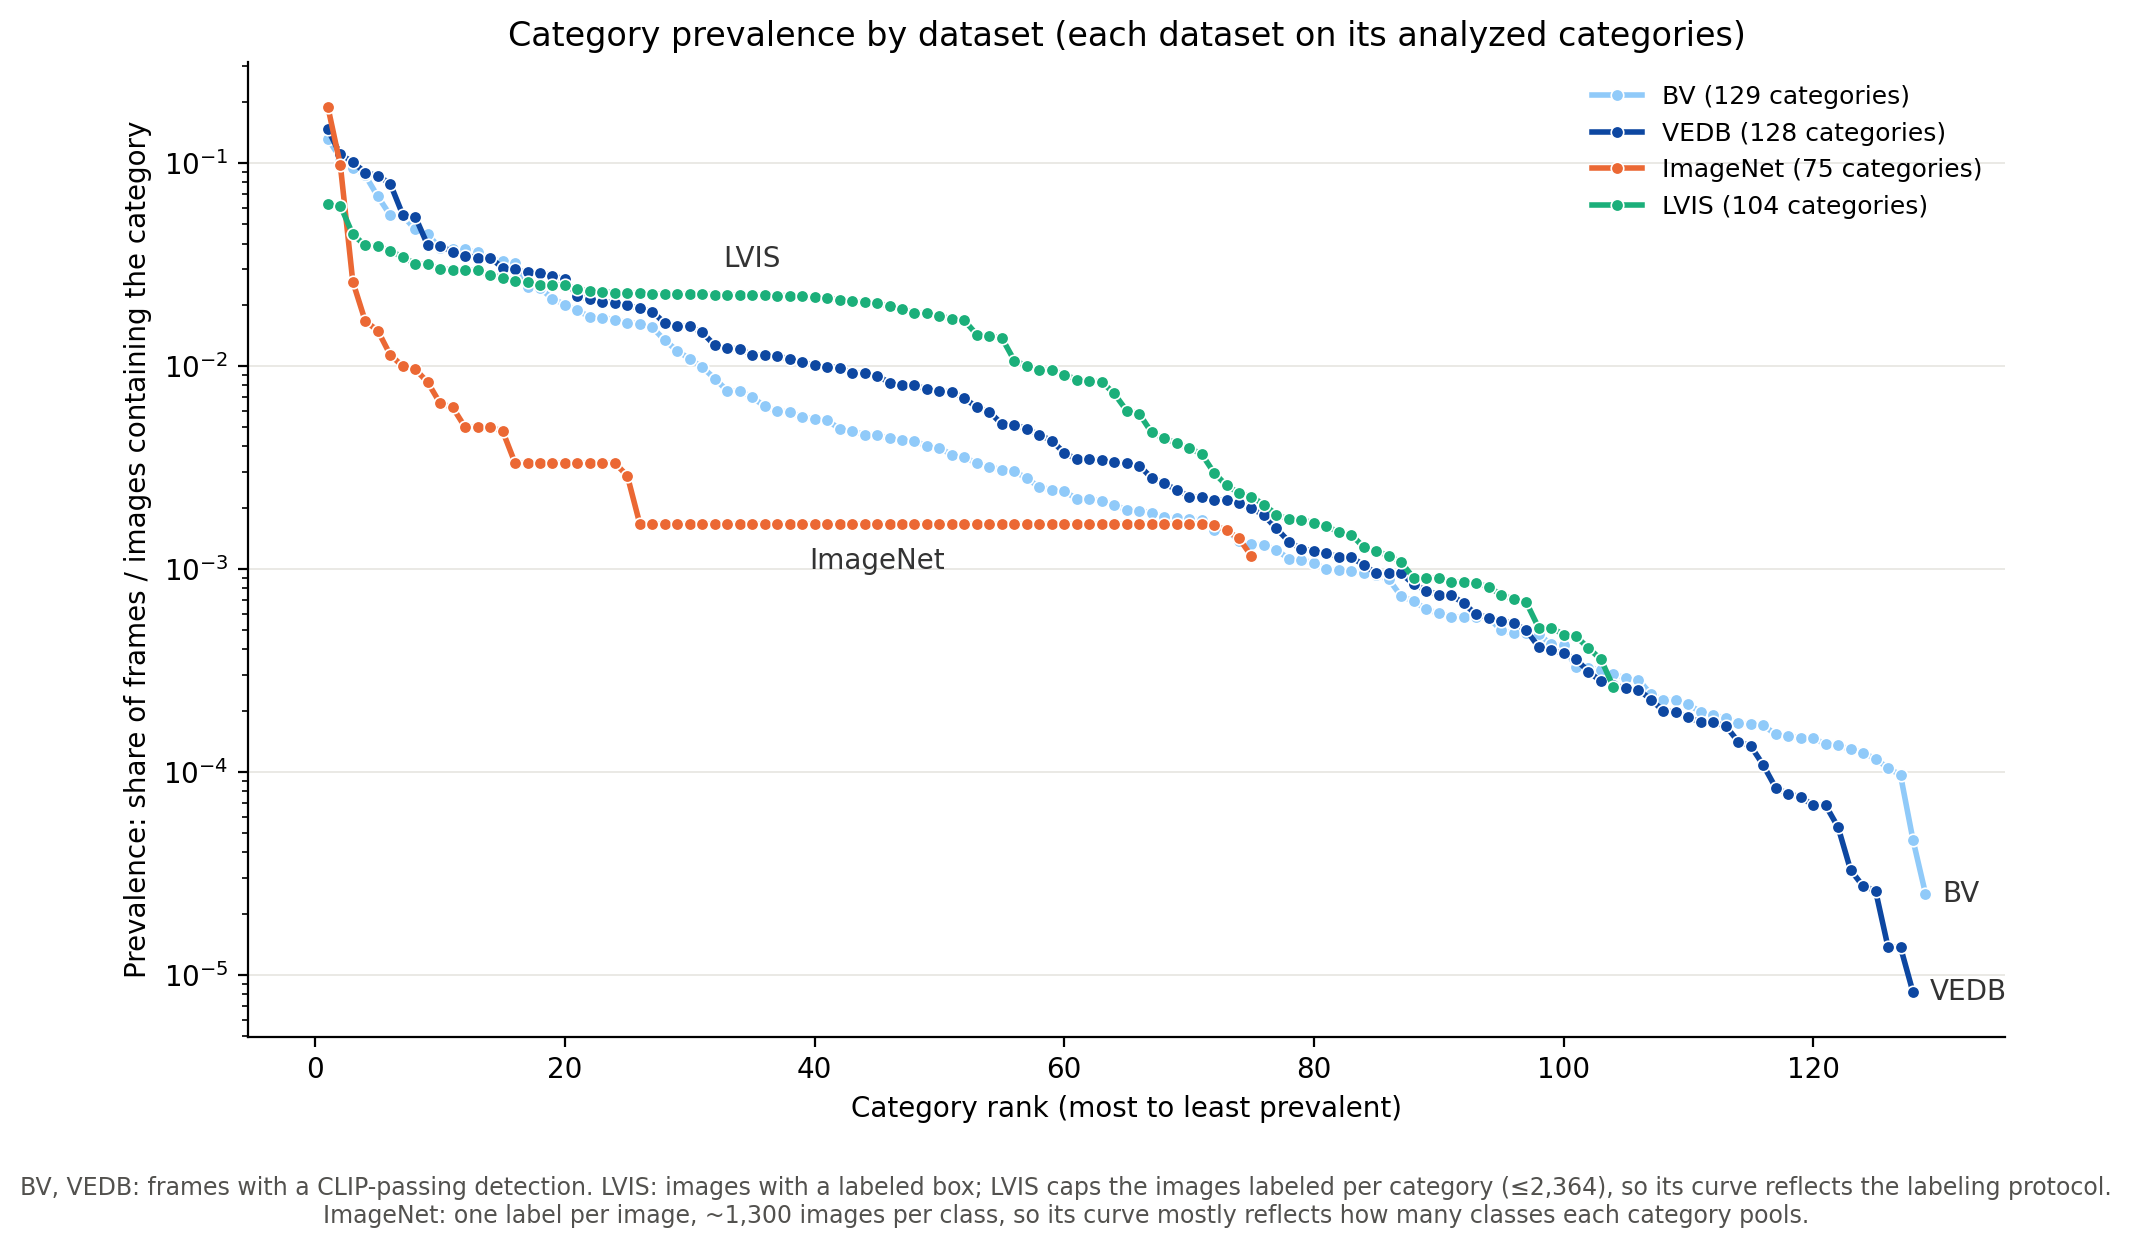

`outputs/category_prevalence/figures/prevalence_shared_categories_bv_vedb_imagenet_lvis.png`

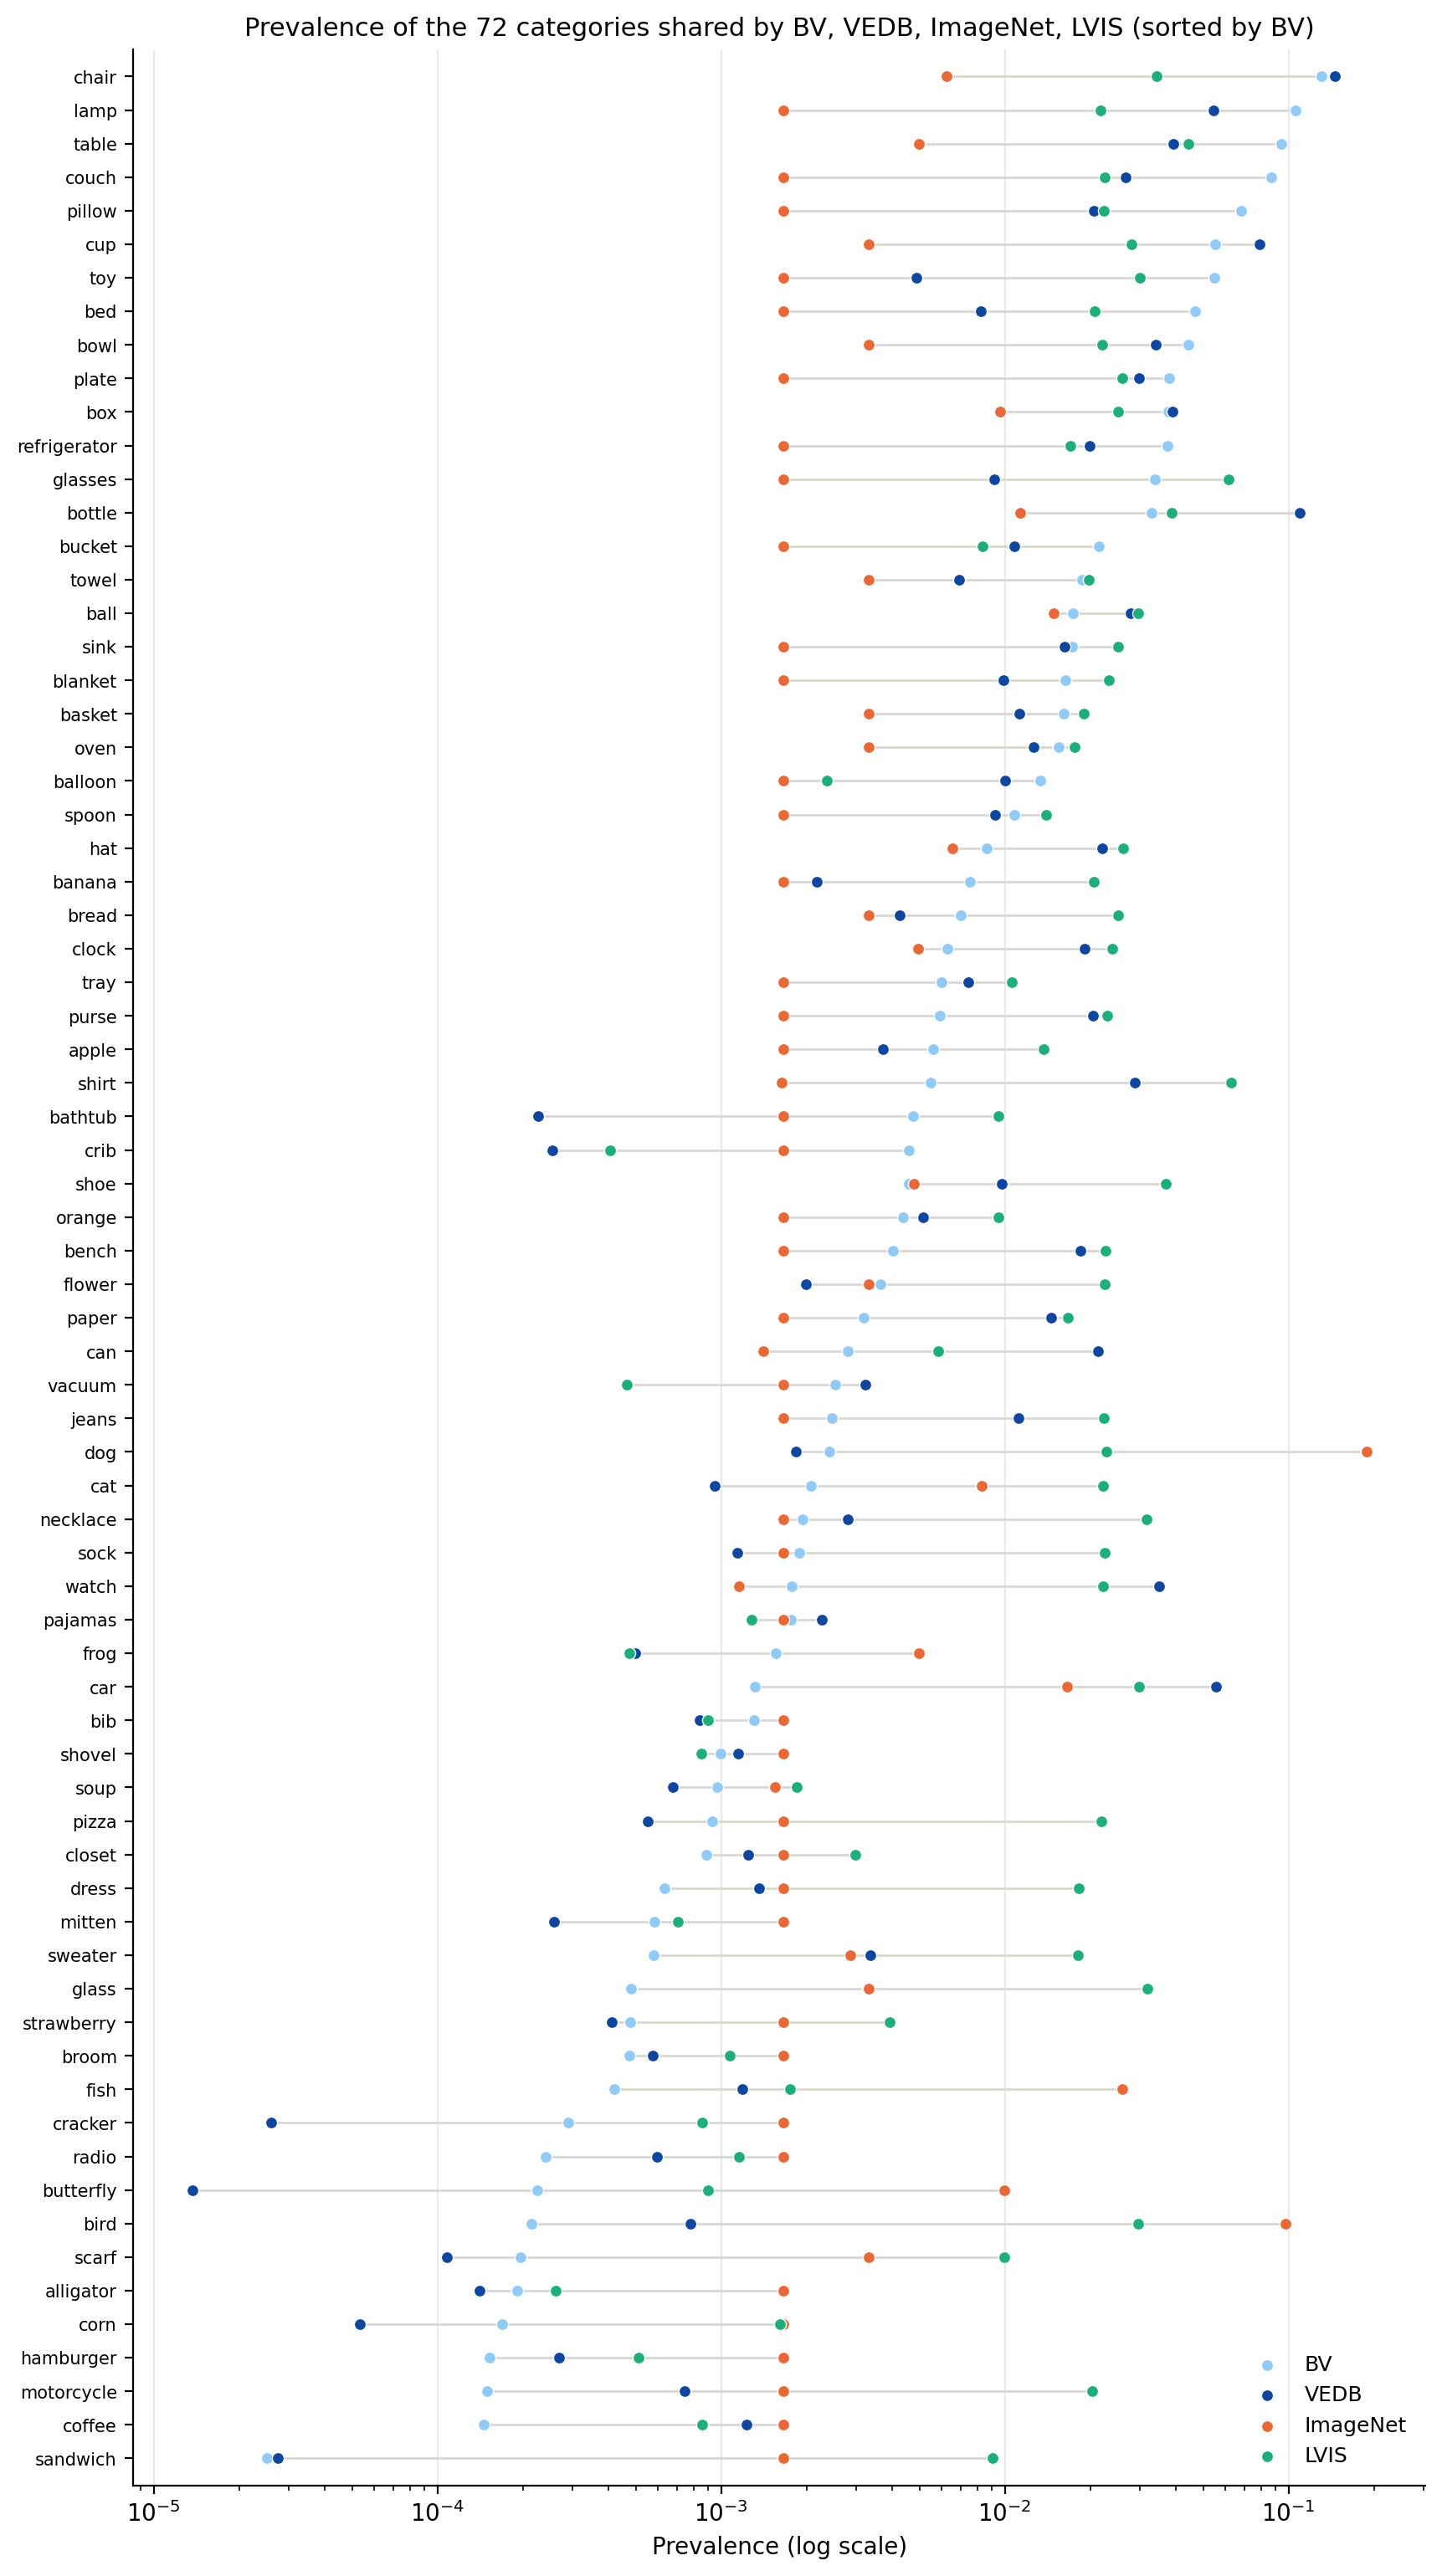

`outputs/category_prevalence/figures/prevalence_native_imagenet_lvis.png`

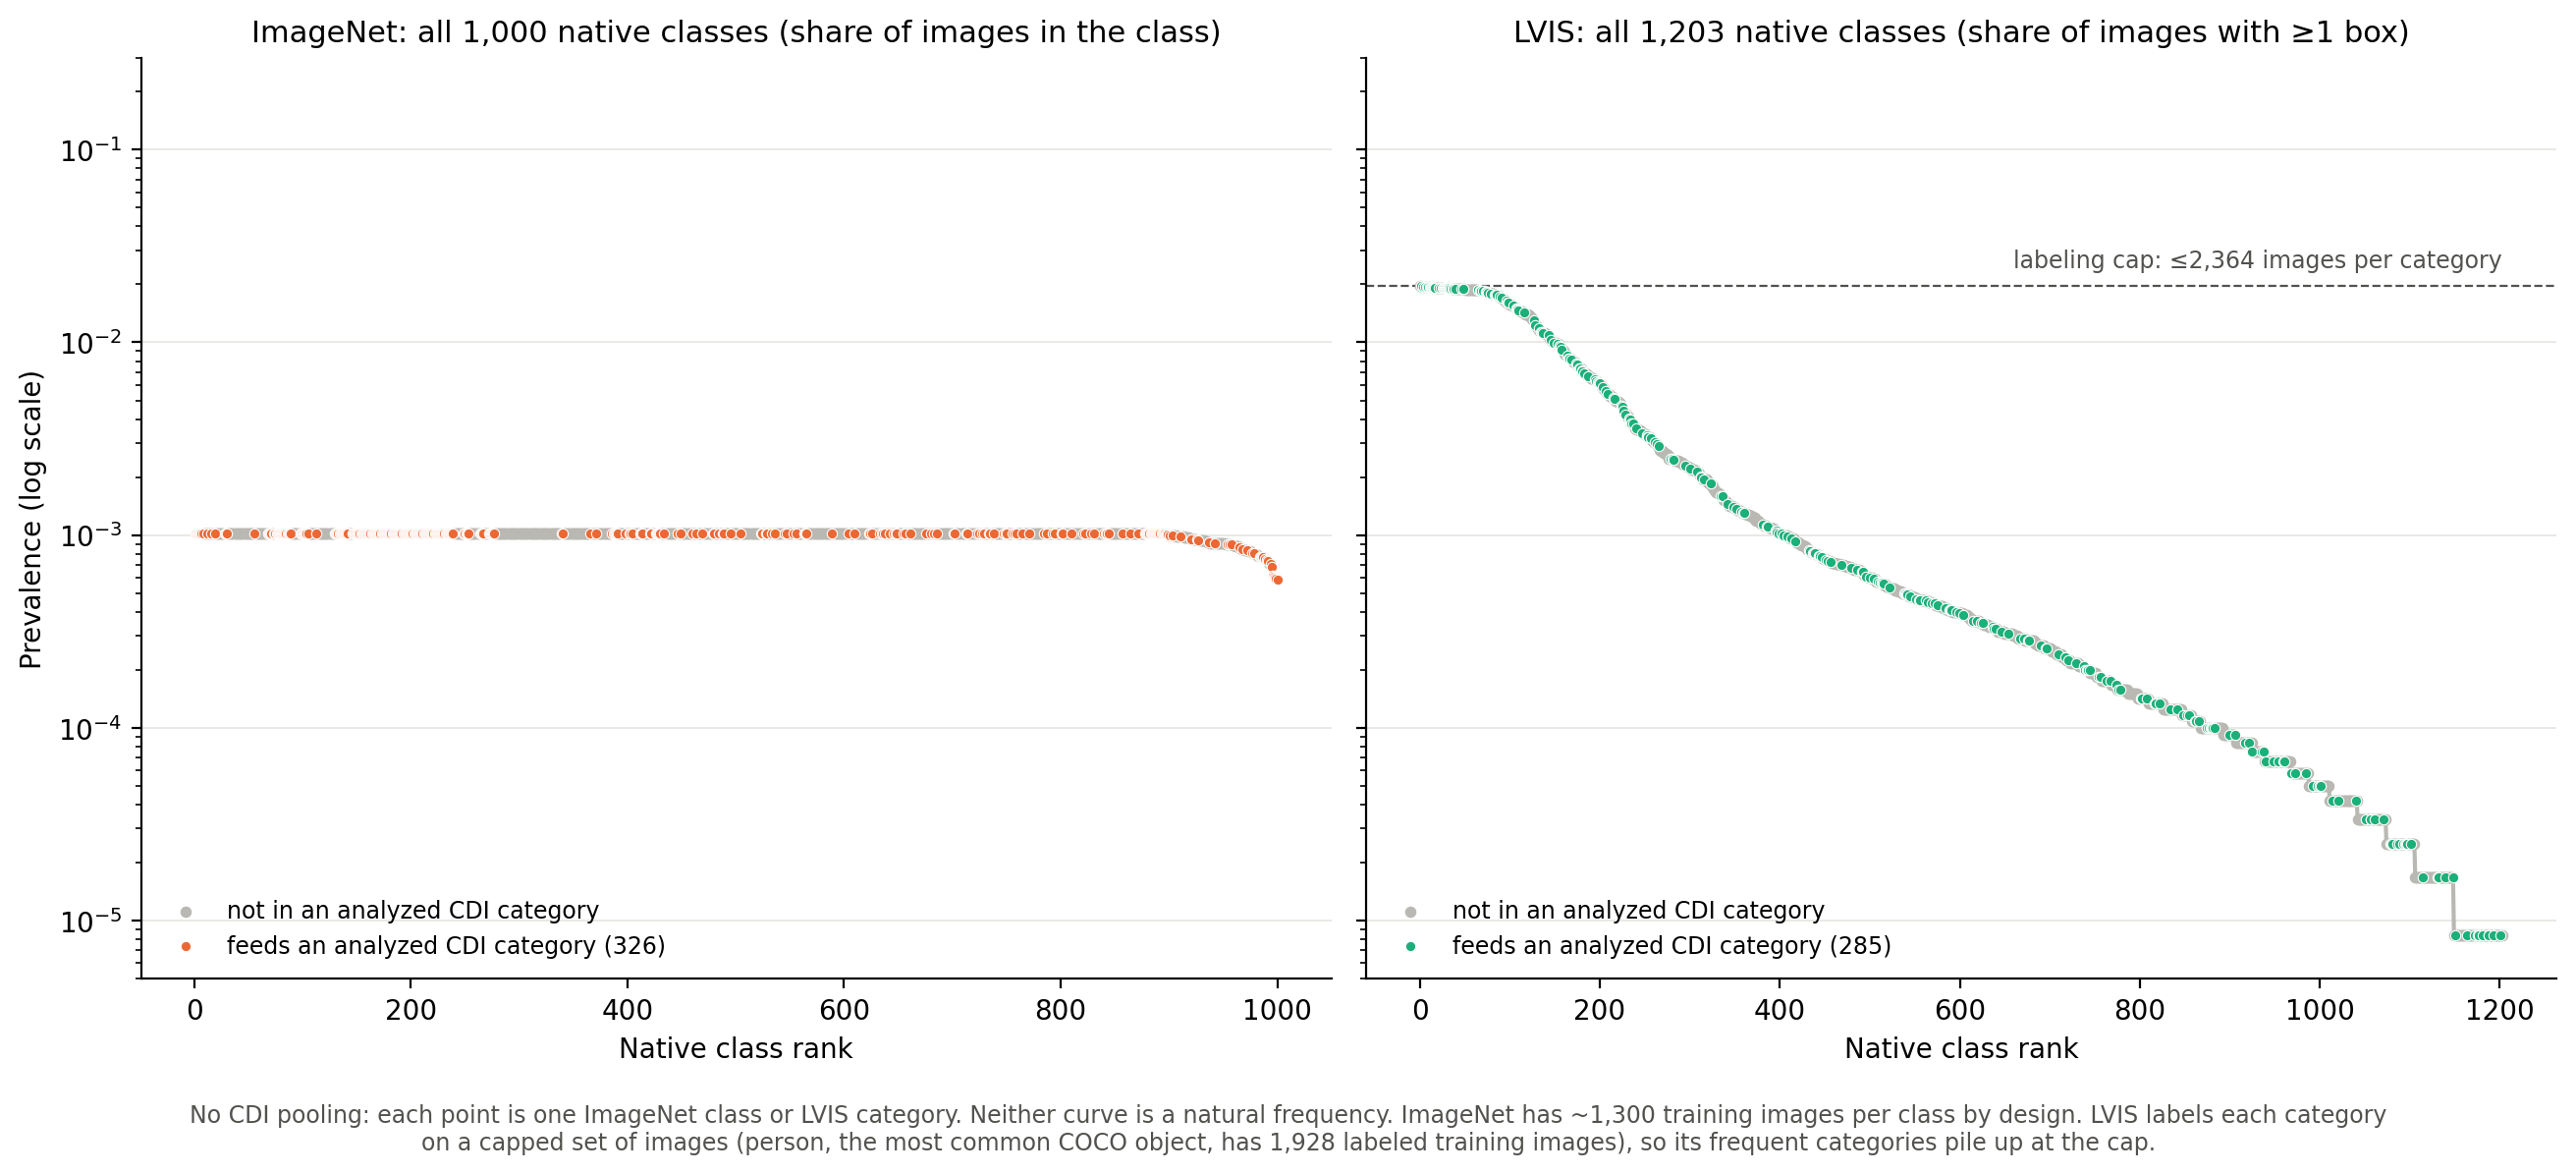

In [9]:
t = "_".join(DATASETS)
f = OUT / "category_prevalence" / "figures"
native = [d for d in DATASETS if d in ("imagenet", "lvis")]
paths = [f / f"prevalence_rank_curves_{t}.png"]
if len(DATASETS) >= 2:
    paths.append(f / f"prevalence_shared_categories_{t}.png")
if native:
    paths.append(f / f"prevalence_native_{'_'.join(native)}.png")
show_images(paths)

### Review checklist

- Is each dataset's denominator the right pool?
- Is prevalence comparable only between BV and VEDB, given ImageNet's fixed class sizes and LVIS's labeling cap?